# 채널 LES 검증 — Re_τ 180 (같은 Re 참조가 있는 케이스만)

비교 기준 = **같은 Re_τ 의 참조**: 자체 DNS 256³ (Re_τ 180.9, 오차의 분모) 와 MKM 1999 (Re_τ 182).
Re_τ 360 캠페인(Vreman 2004 조건)은 같은 Re 의 참조가 없어(MKM 395 로 대체했었다) **이 노트북에서 뺐다** — 데이터는 `stats_re360_*` 에 남아 있다.

| 격자 | Δx⁺ × Δy⁺, z⁺₁ | 케이스 (전부 mirror 벽) |
|---|---|---|
| 64³, 4π×2π×2 | 35 × 18, 1.8 | 모델 없음 · Vreman C_s 0.12 · WALE C_w 0.5 |
| 96³, 같은 상자 | 24 × 12, 1.2 | 모델 없음 · Vreman C_s 0.12 |

각 케이스는 **CPU(np 4·16) 와 GPU(2×A100) 두 번** 돌렸다(2026-10-11). 같은 결과가 나오는지가 §5.
구성 — §1 요약 표 · §2 판정 막대 · §3 평균 속도 · §4 rms·와점성 · §5 CPU vs GPU.
value 벽(1차) 과 Vreman C_s 0.17 런은 `SHOW_EXTRA = True` 로 §1·§3 에 추가된다.

In [1]:
import glob, os, re
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

APP = os.path.abspath(os.path.join(os.getcwd(), ".."))
HERE = os.getcwd()
NU = 1.0 / 2857.0

# 모델은 색, 격자는 선 종류 (64³ 실선, 96³ 파선). 색은 범주형 팔레트 고정 순서.
MODEL_COLOR = {"none": "#8a8984", "vreman": "#2a78d6", "wale": "#1baf7a", "vreman017": "#eda100", "value": "#e87ba4"}
GRID_LS = {64: "-", 96: "--"}
CASES = [
    dict(key="les64_none_mirror",      grid=64, model="none",   label="64^3 no model"),
    dict(key="les64_vreman012_mirror", grid=64, model="vreman", label="64^3 Vreman 0.12"),
    dict(key="les64_wale_mirror",      grid=64, model="wale",   label="64^3 WALE 0.5"),
    dict(key="les96_none_mirror",      grid=96, model="none",   label="96^3 no model"),
    dict(key="les96_vreman012_mirror", grid=96, model="vreman", label="96^3 Vreman 0.12"),
]
SHOW_EXTRA = False
EXTRA = [
    dict(key="les64_vreman012", grid=64, model="value",     label="64^3 Vreman 0.12, value wall"),
    dict(key="les64_vreman017", grid=64, model="vreman017", label="64^3 Vreman 0.17, value wall"),
]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2.0, "legend.frameon": False, "legend.fontsize": 8,
})

In [2]:
def read_stats(path):
    meta = {}
    for line in open(path):
        if line.startswith("#"):
            for k, v in re.findall(r"(\w+)=([-0-9.eE+]+)", line): meta[k] = float(v)
    d = np.loadtxt(path, comments="#")
    nz = len(d); k = np.arange(nz // 2)
    sym = lambda a, sign=1: 0.5 * (a[k] + sign * a[nz - 1 - k])     # 아래·위 반쪽 평균 (uw 는 반대칭)
    ut = meta["u_tau"]
    return meta, dict(zp=sym(d[:, 1]), Up=sym(d[:, 3]), urms=sym(d[:, 4]) / ut, vrms=sym(d[:, 5]) / ut,
                      wrms=sym(d[:, 6]) / ut, uw=-sym(d[:, 7], -1) / ut**2, nut=sym(d[:, 8]) if d.shape[1] > 8 else 0 * k)

def read_monitor(path):
    rows = []
    for line in open(path):
        parts = line.split()
        if len(parts) == 9 and re.match(r"^\s+\d+\s", line):
            rows.append([float(x) for x in parts])
    d = np.array(rows)
    return dict(step=d[:, 0], time=d[:, 1], re_tau=d[:, 6])

def load(case, backend):
    suffix = "_gpu" if backend == "gpu" else ""
    paths = sorted(glob.glob(f"{APP}/stats_{case['key']}{suffix}/channel_stats_*.dat"))
    if not paths: return None
    meta, prof = read_stats(paths[-1])
    log = f"{APP}/log/{case['key']}{suffix}.log"
    return dict(case, backend=backend, meta=meta, prof=prof, monitor=read_monitor(log) if os.path.exists(log) else None)

runs = [r for c in CASES + (EXTRA if SHOW_EXTRA else []) for b in ("cpu", "gpu") for r in [load(c, b)] if r]
cpu = [r for r in runs if r["backend"] == "cpu"]; gpu = {r["key"]: r for r in runs if r["backend"] == "gpu"}
print(f"{len(cpu)} CPU runs, {len(gpu)} GPU runs")

# 참조: 자체 DNS 256³ (기준선) + MKM 180
dns_meta, dns = read_stats(sorted(glob.glob(f"{APP}/stats_re180_ref/channel_stats_*.dat"))[-1])
mean = np.loadtxt(f"{HERE}/ref_mean_180.txt", comments="%"); fluc = np.loadtxt(f"{HERE}/ref_fluc_180.txt", comments="%")
mkm = dict(zp=mean[:, 1], Up=mean[:, 2], urms=np.sqrt(fluc[:, 2]), wrms=np.sqrt(fluc[:, 3]), vrms=np.sqrt(fluc[:, 4]), uw=-fluc[:, 5])
RE_REF = dns_meta["Re_tau"]
print(f"reference: DNS 256^3 Re_tau {RE_REF:.2f}, MKM 1999 Re_tau {mean[-1, 1] / mean[-1, 0]:.1f}")

5 CPU runs, 5 GPU runs
reference: DNS 256^3 Re_tau 180.87, MKM 1999 Re_tau 182.1


## 1. 요약 표 (CPU 런 기준, 오차 분모 = DNS 256³)

판정 기준: Re_τ ±3%, U⁺ 로그 영역(30 < z⁺ < 0.3 Re_τ) RMS < 0.3, rms 피크 ±10%.

In [3]:
def metrics(r):
    p = r["prof"]; re_tau = r["meta"]["Re_tau"]
    mask = (p["zp"] > 30) & (p["zp"] < 0.3 * re_tau)
    log_rms = float(np.sqrt(np.mean((p["Up"][mask] - np.interp(p["zp"][mask], dns["zp"], dns["Up"])) ** 2)))
    peak = {k: 100 * (p[k].max() / dns[k].max() - 1) for k in ("urms", "vrms", "wrms", "uw")}
    near = (p["zp"] > 0.5) & (p["zp"] < 15) & (p["nut"] > 1e-12)
    slope = float(np.polyfit(np.log(p["zp"][near]), np.log(p["nut"][near]), 1)[0]) if near.sum() >= 3 else float("nan")
    return dict(re=re_tau, re_err=100 * (re_tau / RE_REF - 1), log_rms=log_rms, peak=peak, slope=slope)
for r in runs: r["m"] = metrics(r)
print(f"{'case':<30} {'Re_tau':>7} {'err':>6} {'U+ logRMS':>9} {'urms':>6} {'vrms':>6} {'wrms':>6} {'-uw':>6} {'nu_t~z+^n':>9}")
for r in cpu:
    m = r["m"]; pk = m["peak"]
    ok = abs(m["re_err"]) <= 3 and m["log_rms"] < 0.3
    print(f"{r['label']:<30} {m['re']:7.1f} {m['re_err']:+5.1f}% {m['log_rms']:9.2f} {pk['urms']:+5.0f}% {pk['vrms']:+5.0f}% "
          f"{pk['wrms']:+5.0f}% {pk['uw']:+5.0f}% {m['slope']:9.2f}   {'PASS' if ok else '-'}")

case                            Re_tau    err U+ logRMS   urms   vrms   wrms    -uw nu_t~z+^n
64^3 no model                    193.9  +7.2%      1.09   +11%   -10%   -10%   -10%       nan   -
64^3 Vreman 0.12                 181.8  +0.5%      0.09   +11%   -17%   -15%   -12%      0.99   PASS
64^3 WALE 0.5                    180.3  -0.3%      0.29   +14%   -19%   -17%   -12%      2.63   PASS
96^3 no model                    193.0  +6.7%      1.02    +1%    -6%    -3%    -4%       nan   -
96^3 Vreman 0.12                 184.6  +2.0%      0.18    +4%    -9%    -7%    -6%      1.00   PASS


## 2. 판정 — Re_τ 오차와 U⁺ 로그 영역 RMS

막대 = CPU, 점 = 같은 케이스의 GPU 런. 초록 띠/선이 통과 기준.

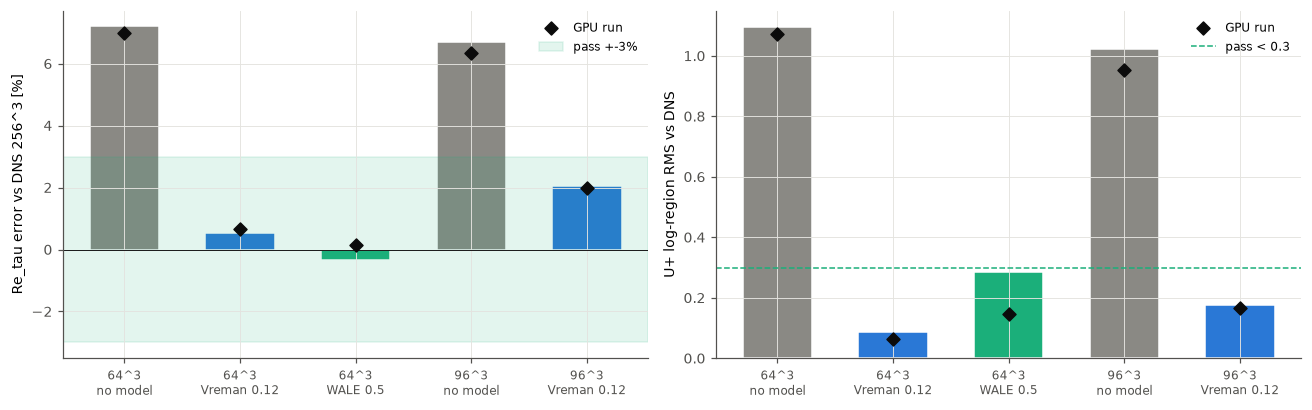

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(12, 3.8))
x = np.arange(len(cpu)); labels = [r["label"].replace(" ", "\n", 1) for r in cpu]
for ax, key, band in ((axes[0], "re_err", 3), (axes[1], "log_rms", 0.3)):
    ax.bar(x, [r["m"][key] for r in cpu], width=0.6, color=[MODEL_COLOR[r["model"]] for r in cpu],
           edgecolor=["white"] * len(cpu), hatch=None)
    for i, r in enumerate(cpu):
        if r["key"] in gpu: ax.scatter(i, gpu[r["key"]]["m"][key], marker="D", s=36, color=INK, zorder=5,
                                       label="GPU run" if i == 0 else None)
    if key == "re_err": ax.axhspan(-band, band, color="#1baf7a", alpha=0.12, label="pass +-3%"); ax.set_ylabel("Re_tau error vs DNS 256^3 [%]")
    else: ax.axhline(band, color="#1baf7a", ls="--", lw=1, label="pass < 0.3"); ax.set_ylabel("U+ log-region RMS vs DNS")
    ax.axhline(0, color=INK, lw=0.6); ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8); ax.legend(loc="upper right")
figure.tight_layout(); plt.show()

## 3. 평균 속도 U⁺ 와 DNS 와의 차이

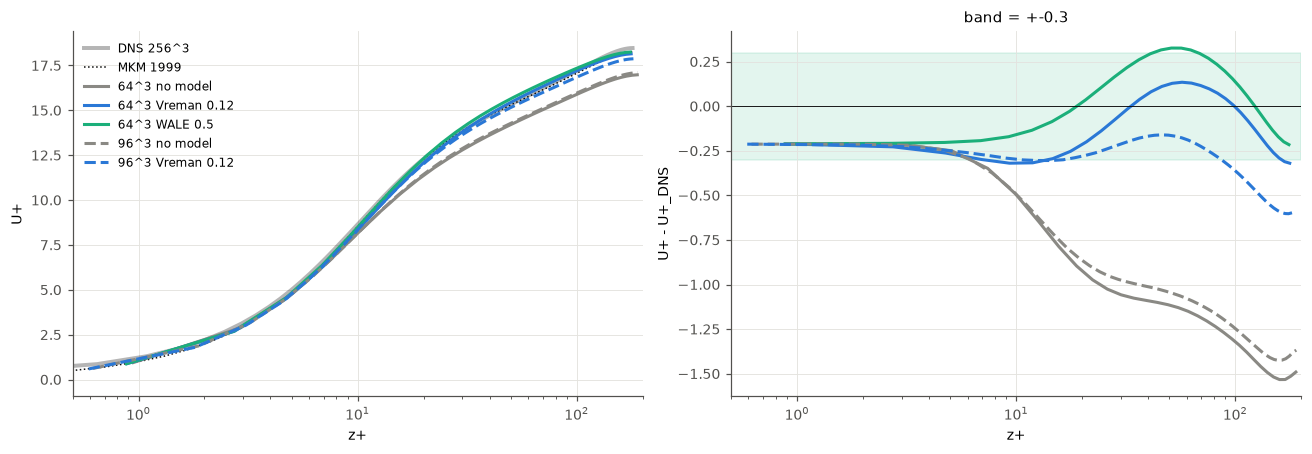

In [5]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].semilogx(dns["zp"], dns["Up"], color=INK, lw=2.6, alpha=0.3, label="DNS 256^3")
axes[0].semilogx(mkm["zp"], mkm["Up"], color=INK, lw=1, ls=":", label="MKM 1999")
for r in cpu:
    p = r["prof"]; style = dict(color=MODEL_COLOR[r["model"]], ls=GRID_LS[r["grid"]])
    axes[0].semilogx(p["zp"], p["Up"], label=r["label"], **style)
    axes[1].semilogx(p["zp"], p["Up"] - np.interp(p["zp"], dns["zp"], dns["Up"]), **style)
axes[1].axhspan(-0.3, 0.3, color="#1baf7a", alpha=0.12); axes[1].axhline(0, color=INK, lw=0.6)
axes[0].set_xlim(0.5, 200); axes[0].set_ylabel("U+"); axes[0].legend()
axes[1].set_xlim(0.5, 200); axes[1].set_ylabel("U+ - U+_DNS"); axes[1].set_title("band = +-0.3")
for ax in axes: ax.set_xlabel("z+")
figure.tight_layout(); plt.show()

## 4. rms·전단응력과 와점성

rms 결손은 64³→96³ 에서 줄어든다 = 수평 해상도 효과(모델 탓 아님). ν_t 벽 근처 기울기: Vreman 이론 1, WALE 이론 3.

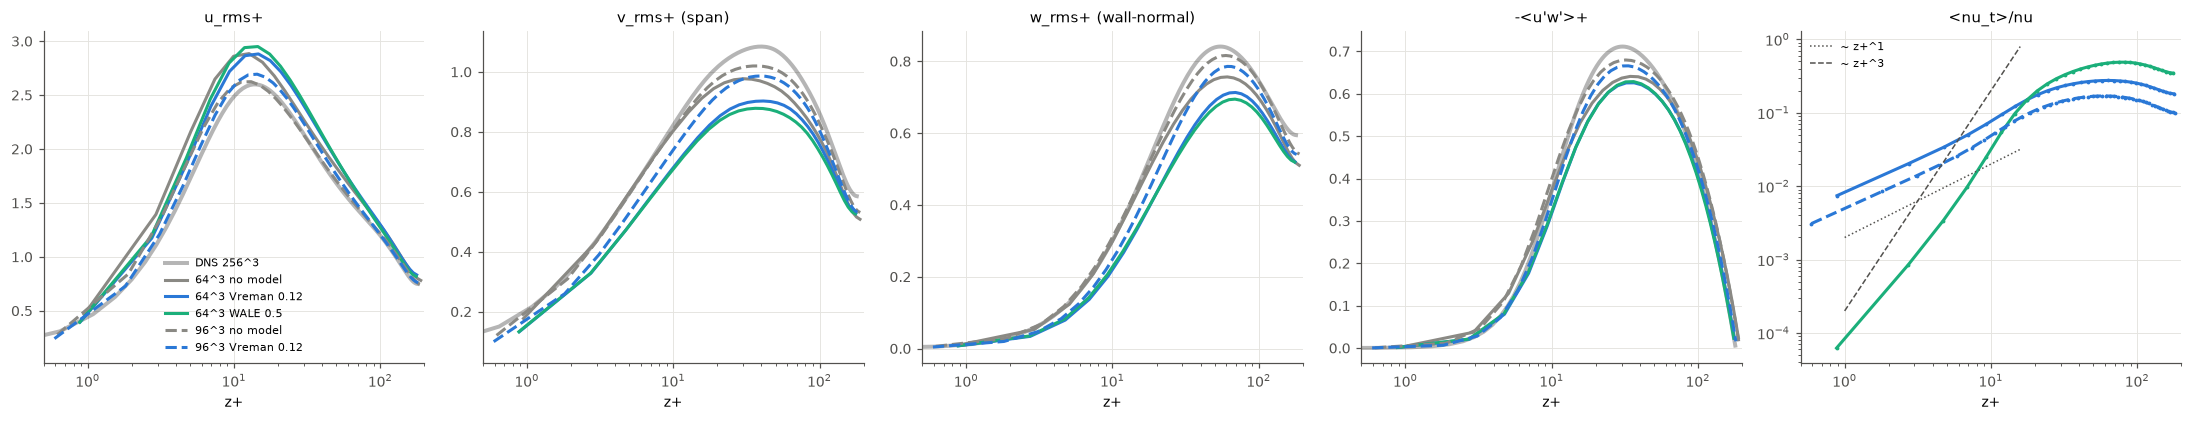

In [6]:
panels = [("urms", "u_rms+"), ("vrms", "v_rms+ (span)"), ("wrms", "w_rms+ (wall-normal)"), ("uw", "-<u'w'>+")]
figure, axes = plt.subplots(1, 5, figsize=(20, 3.9))
for ax, (key, title) in zip(axes, panels):
    ax.plot(dns["zp"], dns[key], color=INK, lw=2.6, alpha=0.3, label="DNS 256^3")
    for r in cpu: ax.plot(r["prof"]["zp"], r["prof"][key], color=MODEL_COLOR[r["model"]], ls=GRID_LS[r["grid"]], label=r["label"])
    ax.set_xscale("log"); ax.set_xlim(0.5, 200); ax.set_xlabel("z+"); ax.set_title(title)
axes[0].legend(fontsize=7)
ax = axes[4]
for r in cpu:
    p = r["prof"]; good = p["nut"] > 1e-12
    if good.any(): ax.loglog(p["zp"][good], p["nut"][good], color=MODEL_COLOR[r["model"]], ls=GRID_LS[r["grid"]], marker=".", ms=3)
zl = np.logspace(0, 1.2, 10)
ax.loglog(zl, 2e-3 * zl, color=MUTED, lw=1, ls=":", label="~ z+^1"); ax.loglog(zl, 2e-4 * zl**3, color=MUTED, lw=1, ls="--", label="~ z+^3")
ax.set_xlim(0.5, 200); ax.set_xlabel("z+"); ax.set_title("<nu_t>/nu"); ax.legend(fontsize=7)
figure.tight_layout(); plt.show()

## 5. CPU vs GPU

같은 덱(분할만 npz 4·16 → 2)을 CPU 와 GPU 에서 돌렸다. 짧은 결정론 대조(64³ Vreman, 300 스텝)에서는 모니터 값(u_τ, Re_τ, −dP/dx)이 **출력 자릿수까지 동일**했다(`log/detcheck_*.log`).
긴 런은 혼돈이라 순간장은 갈라지고, 통계가 같은지를 본다: 위 = 케이스별 Re_τ 이력, 아래 = U⁺·u_rms⁺ 겹침(실선 CPU, 점선 GPU).

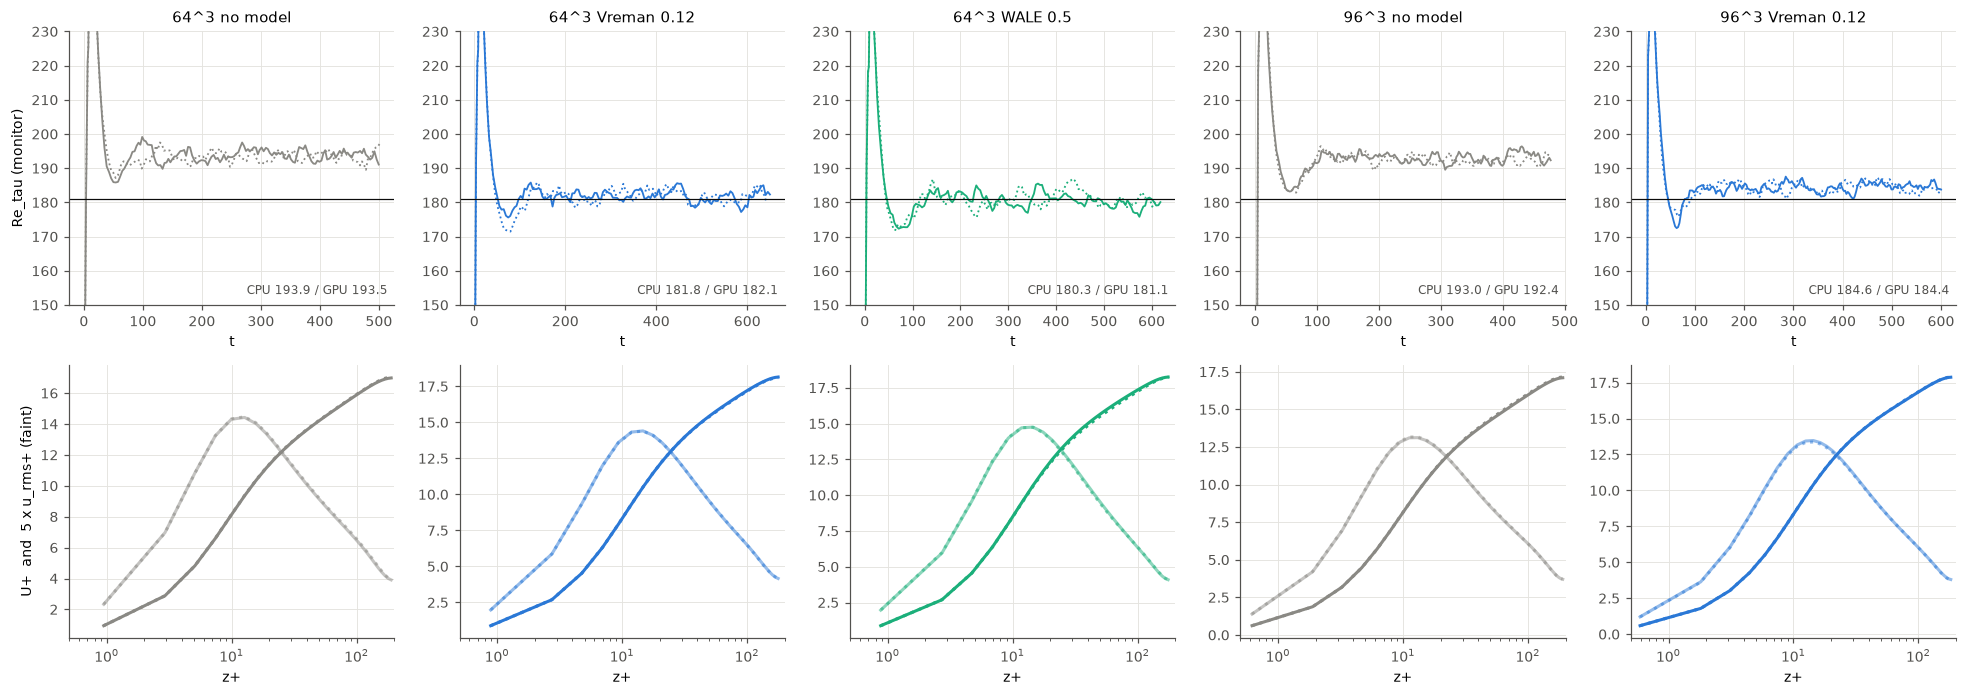

case                   Re_tau CPU     GPU   diff | U+ logRMS CPU   GPU
64^3 no model              193.89  193.52  -0.2% |          1.09  1.07
64^3 Vreman 0.12           181.81  182.08  +0.1% |          0.09  0.06
64^3 WALE 0.5              180.28  181.12  +0.5% |          0.29  0.15
96^3 no model              193.00  192.36  -0.3% |          1.02  0.95
96^3 Vreman 0.12           184.57  184.44  -0.1% |          0.18  0.17


In [7]:
pairs = [r for r in cpu if r["key"] in gpu]
figure, axes = plt.subplots(2, len(pairs), figsize=(3.6 * len(pairs), 6.4), squeeze=False)
for col, r in enumerate(pairs):
    g = gpu[r["key"]]; color = MODEL_COLOR[r["model"]]
    ax = axes[0, col]
    for run, ls in ((r, "-"), (g, ":")):
        if run["monitor"] is not None: ax.plot(run["monitor"]["time"], run["monitor"]["re_tau"], color=color, ls=ls, lw=1.2)
    ax.axhline(RE_REF, color=INK, lw=0.8); ax.set_title(r["label"]); ax.set_xlabel("t"); ax.set_ylim(150, 230)
    ax.text(0.98, 0.04, f"CPU {r['m']['re']:.1f} / GPU {g['m']['re']:.1f}", transform=ax.transAxes, ha="right", fontsize=8, color=MUTED)
    ax = axes[1, col]
    for run, ls in ((r, "-"), (g, ":")):
        ax.semilogx(run["prof"]["zp"], run["prof"]["Up"], color=color, ls=ls)
        ax.semilogx(run["prof"]["zp"], 5 * run["prof"]["urms"], color=color, ls=ls, alpha=0.5)
    ax.set_xlim(0.5, 200); ax.set_xlabel("z+")
axes[0, 0].set_ylabel("Re_tau (monitor)"); axes[1, 0].set_ylabel("U+  and  5 x u_rms+ (faint)")
figure.tight_layout(); plt.show()
print(f"{'case':<22} {'Re_tau CPU':>10} {'GPU':>7} {'diff':>6} | {'U+ logRMS CPU':>13} {'GPU':>5}")
for r in pairs:
    g = gpu[r["key"]]
    print(f"{r['label']:<22} {r['m']['re']:10.2f} {g['m']['re']:7.2f} {100*(g['m']['re']/r['m']['re']-1):+5.1f}% | {r['m']['log_rms']:13.2f} {g['m']['log_rms']:5.2f}")